# Tier 3 - Roll and pitch, motion disturbances, accelerometer gating, phyphox data

Methods: **accel** (tilt), **CF** (roll/pitch complementary filter, tau = 0.2 s), **KF** (two decoupled 2-state Kalman filters, roll with b_x and pitch with b_y) and **KF-gated** (KF with accelerometer gating, threshold 0.2 m/s^2). All filter parameters except the bias random-walk intensity are estimated from an initial stationary window (`estimate_stationary`). Ground truth (`*_true`) is used only for metrics and plots, never passed to a filter. Code works in rad and rad/s; angles are shown in degrees, rates in rad/s and deg/s.

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import ipywidgets as widgets

import imu_sim
import imu_filters
import imu_metrics
import imu_plots
import imu_io

DEG = np.rad2deg
TAU = 0.2
GATE_THRESHOLD = 0.2          # m/s^2
BIAS_RW_STD = 1e-4            # rad/s/sqrt(s), the only filter parameter not estimated from data
METHODS = ['accel', 'CF', 'KF', 'KF-gated']
ANGLES = ['roll', 'pitch']

def show(fig):
    display(fig)
    plt.close(fig)

def run_methods(t, gyro, accel, rest_window, tau=TAU, q_scale=1.0, r_scale=1.0, gate_threshold=GATE_THRESHOLD):
    # Only measured data (t, gyro, accel) goes in. Filter parameters come from the rest window.
    est = imu_filters.estimate_stationary(t, gyro, accel, rest_window[0], rest_window[1])
    acc_roll, acc_pitch = imu_filters.accel_tilt(accel)
    cf = imu_filters.complementary_roll_pitch(t, gyro, accel, tau=tau, gyro_bias=est.gyro_bias)
    kw = dict(gyro_noise_std=est.gyro_noise_std * np.sqrt(q_scale),
              accel_noise_std=est.accel_noise_std * np.sqrt(r_scale),
              bias_rw_std=BIAS_RW_STD * np.sqrt(q_scale),
              gravity=est.gravity, gyro_bias_z=est.gyro_bias[2],
              initial_bias=(est.gyro_bias[0], est.gyro_bias[1]))
    kf = imu_filters.kalman_roll_pitch(t, gyro, accel, **kw)
    kfg = imu_filters.kalman_roll_pitch(t, gyro, accel, gate_threshold=gate_threshold, **kw)
    angles = {'accel': (acc_roll, acc_pitch), 'CF': cf, 'KF': (kf.roll, kf.pitch), 'KF-gated': (kfg.roll, kfg.pitch)}
    return est, angles, kf, kfg

## Clean run (S6: 120 s, 100 Hz, no disturbances, seed 0)

The rest phase lasts until t = 5 s; the stationary window for parameter estimation is 0-4.5 s.

Estimated from the rest window: gyro bias (rad/s) = [0.00924 0.01029 0.0101 ], gyro noise = 0.0049 rad/s, accel noise = 0.0509 m/s^2, gravity = 9.8083 m/s^2

method       roll RMSE (deg)  pitch RMSE (deg)   (samples with t >= 20 s)
accel                 0.3114            0.2882
CF                    0.0532            0.0453
KF                    0.0368            0.0270
KF-gated              0.0368            0.0270


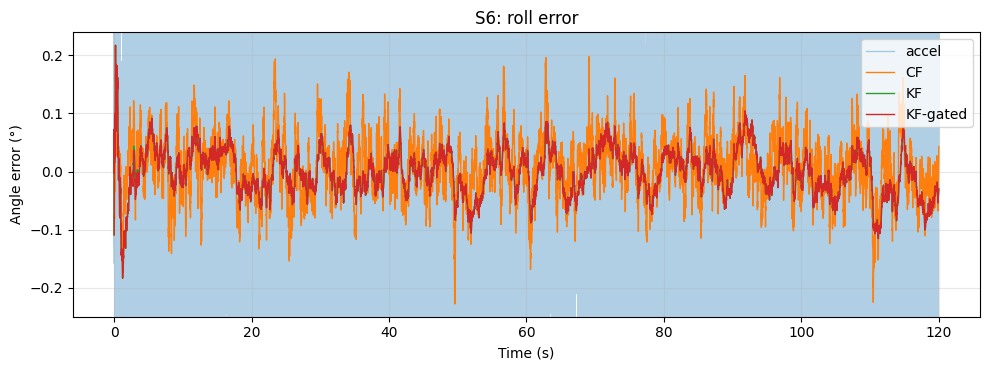

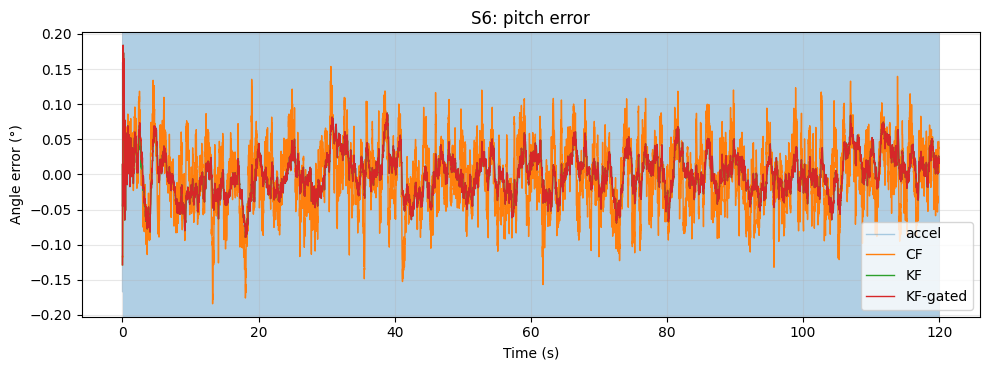

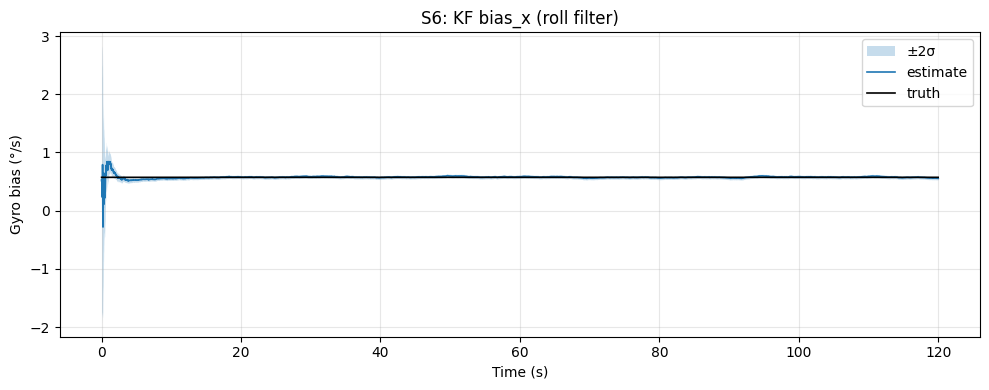

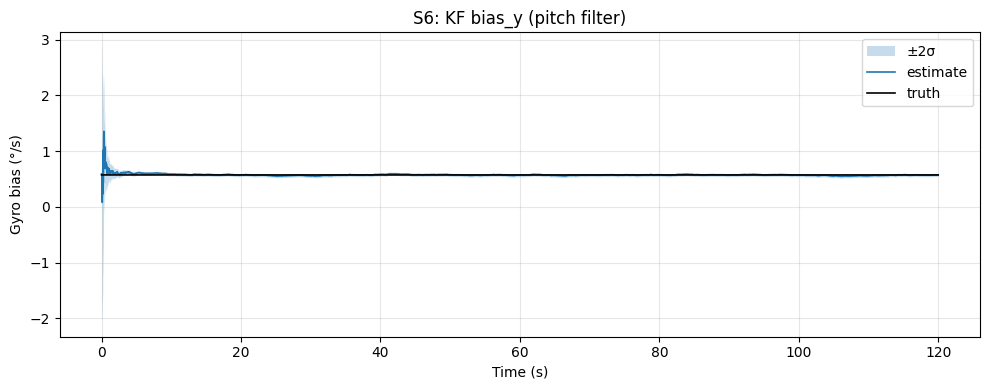

In [11]:
sim6 = imu_sim.simulate_roll_pitch_imu(seed=0)
est6, ang6, kf6, kfg6 = run_methods(sim6.t, sim6.gyro, sim6.accel, (0.0, 4.5))
truth6 = (sim6.roll_true, sim6.pitch_true)
m6 = sim6.t >= 20.0

print('Estimated from the rest window: gyro bias (rad/s) = %s, gyro noise = %.4f rad/s, accel noise = %.4f m/s^2, gravity = %.4f m/s^2'
      % (np.round(est6.gyro_bias, 5), est6.gyro_noise_std, est6.accel_noise_std, est6.gravity))
print()
print('%-10s%18s%18s' % ('method', 'roll RMSE (deg)', 'pitch RMSE (deg)') + '   (samples with t >= 20 s)')
for name in METHODS:
    vals = [DEG(imu_metrics.rmse(ang6[name][i][m6], truth6[i][m6])) for i in range(2)]
    print('%-10s%18.4f%18.4f' % (name, vals[0], vals[1]))

for i, angle in enumerate(ANGLES):
    show(imu_plots.plot_error_comparison(sim6.t, truth6[i], {n: ang6[n][i] for n in METHODS},
                                         background=('accel',), title='S6: %s error' % angle))

n6 = len(sim6.t)
show(imu_plots.plot_bias_estimate(sim6.t, kf6.bias_x, np.sqrt(kf6.cov_roll[:, 1, 1]),
                                  bias_true=np.full(n6, sim6.gyro_bias[0]), title='S6: KF bias_x (roll filter)'))
show(imu_plots.plot_bias_estimate(sim6.t, kf6.bias_y, np.sqrt(kf6.cov_pitch[:, 1, 1]),
                                  bias_true=np.full(n6, sim6.gyro_bias[1]), title='S6: KF bias_y (pitch filter)'))

## Disturbances (S7: 150 s, linear-acceleration pulses at 30 s and 60 s, 15 Hz vibration at 90-95 s, seed 0)

- *Max disturbance error*: maximum absolute error over samples inside a disturbance segment.
- *Recovery time* per segment: time from the segment end until the error stays within 0.5 deg, evaluated in the window up to the next segment (windows [32, 60), [62, 90) and [95, 150]).
- *Quiet RMSE*: RMSE over samples with t >= 20 s that are not disturbed and not within 15 s after any segment end.

method    angle       max dist. err (deg)     recovery seg1 / seg2 / seg3 (s)      quiet RMSE (deg)
accel     roll                     19.915                 27.90 / inf / 54.92                0.3151
accel     pitch                    17.519               27.86 / 27.80 / 54.99                0.2913
CF        roll                     17.460                  0.00 / 0.51 / 0.20                0.0501
CF        pitch                    16.290                  0.49 / 0.00 / 0.00                0.0442
KF        roll                     12.449                  0.00 / 2.42 / 0.52                0.0363
KF        pitch                    12.286                  2.36 / 0.00 / 0.11                0.0301
KF-gated  roll                      3.028                  0.00 / 1.21 / 0.00                0.0339
KF-gated  pitch                     2.458                  0.96 / 0.00 / 0.00                0.0278

KF-gated: 829 of 15000 samples gated (5.5 %)


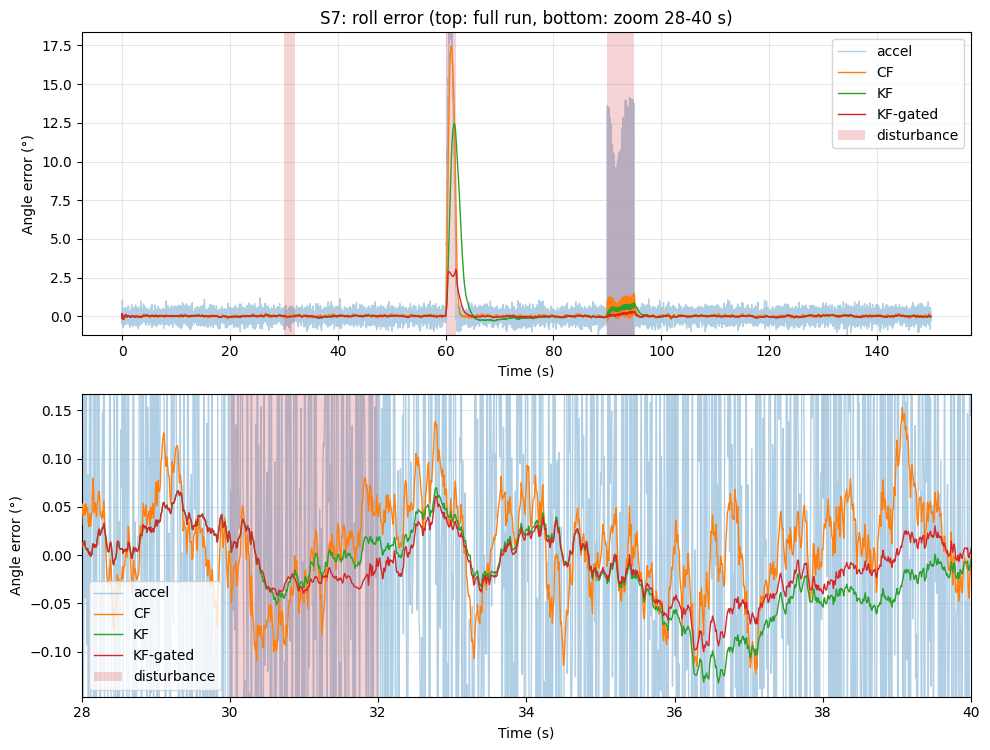

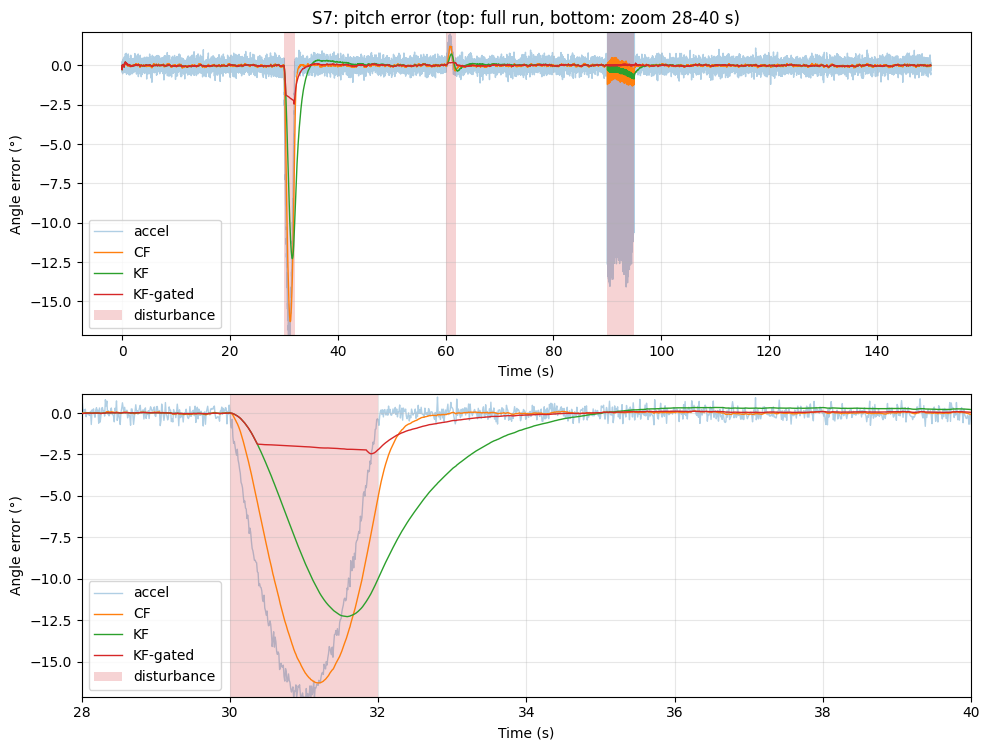

In [12]:
sim7 = imu_sim.simulate_roll_pitch_imu(duration=150.0, linear_accel_segments=imu_sim.DEFAULT_LINEAR_ACCEL_SEGMENTS,
                                         vibration_segments=imu_sim.DEFAULT_VIBRATION_SEGMENTS, seed=0)
est7, ang7, kf7, kfg7 = run_methods(sim7.t, sim7.gyro, sim7.accel, (0.0, 4.5))
truth7 = (sim7.roll_true, sim7.pitch_true)
t7 = sim7.t
dist7 = sim7.disturbed_true
SEG_ENDS = (32.0, 62.0, 95.0)
WINDOWS = ((32.0, 60.0), (62.0, 90.0), (95.0, 150.1))
quiet7 = (t7 >= 20.0) & ~dist7
for e in SEG_ENDS:
    quiet7 &= ~((t7 >= e) & (t7 < e + 15.0))

def recovery(est, truth):
    times = []
    for (w0, w1), e in zip(WINDOWS, SEG_ENDS):
        w = (t7 >= w0) & (t7 < w1)
        times.append(imu_metrics.convergence_time(t7[w], est[w], truth[w], tol=np.deg2rad(0.5)) - e)
    return times

print('%-10s%-7s%24s%36s%22s' % ('method', 'angle', 'max dist. err (deg)', 'recovery seg1 / seg2 / seg3 (s)', 'quiet RMSE (deg)'))
for name in METHODS:
    for i, angle in enumerate(ANGLES):
        est = ang7[name][i]
        mx = DEG(imu_metrics.max_abs_error(est[dist7], truth7[i][dist7]))
        rec = recovery(est, truth7[i])
        q = DEG(imu_metrics.rmse(est[quiet7], truth7[i][quiet7]))
        rec_txt = ' / '.join('%.2f' % r for r in rec)
        print('%-10s%-7s%24.3f%36s%22.4f' % (name, angle, mx, rec_txt, q))

print()
print('KF-gated: %d of %d samples gated (%.1f %%)' % (kfg7.gated.sum(), len(t7), 100.0 * kfg7.gated.mean()))

for i, angle in enumerate(ANGLES):
    show(imu_plots.plot_error_comparison(t7, truth7[i], {n: ang7[n][i] for n in METHODS}, background=('accel',),
                                         t_window=(28, 40), shade=dist7,
                                         title='S7: %s error (top: full run, bottom: zoom 28-40 s)' % angle))

## Real data A (`data/phone_tilts.zip`) and B (`data/phone_disturbances.zip`)

Both recordings are resampled to a common 100 Hz grid. The rest window is t[0] + 1 s ... t[0] + 7 s. Shaded spans in the plots mark samples gated by KF-gated. The end window is [t_last - 7 s, t_last - 1 s]; both recordings end in the starting position.

In [13]:
DATA_FILES = {'A': os.path.join('data', 'phone_tilts.zip'), 'B': os.path.join('data', 'phone_disturbances.zip')}
real = {}
for key, path in DATA_FILES.items():
    rec = imu_io.load_phyphox_zip(path)
    t, gyro, accel = imu_io.resample_common(rec.accel_t, rec.accel, rec.gyro_t, rec.gyro, fs=100.0)
    window = (t[0] + 1.0, t[0] + 7.0)
    est, ang, kf, kfg = run_methods(t, gyro, accel, window)
    real[key] = dict(t=t, gyro=gyro, accel=accel, window=window, est=est, ang=ang, kf=kf, kfg=kfg, rec=rec)
    print('%s: %d accel samples, %d gyro samples, common grid %.1f s (%d samples)'
          % (key, len(rec.accel_t), len(rec.gyro_t), t[-1] - t[0], len(t)))

print()
print('StationaryEstimate over the rest window')
print('%-4s%10s%16s%16s%16s%18s%19s%18s' % ('set', 'n', 'bias_x (rad/s)', 'bias_y (rad/s)', 'bias_z (rad/s)',
                                             'gyro std (rad/s)', 'accel std (m/s^2)', 'gravity (m/s^2)'))
for key, r in real.items():
    e = r['est']
    print('%-4s%10d%16.6f%16.6f%16.6f%18.6f%19.5f%18.4f' % (key, e.n_samples, e.gyro_bias[0], e.gyro_bias[1], e.gyro_bias[2],
                                                       e.gyro_noise_std, e.accel_noise_std, e.gravity))
print()
print('%-4s%16s%16s%16s' % ('set', 'bias_x (deg/s)', 'bias_y (deg/s)', 'bias_z (deg/s)'))
for key, r in real.items():
    e = r['est']
    print('%-4s%16.5f%16.5f%16.5f' % (key, DEG(e.gyro_bias[0]), DEG(e.gyro_bias[1]), DEG(e.gyro_bias[2])))

A: 6020 accel samples, 6020 gyro samples, common grid 60.2 s (6020 samples)
B: 6000 accel samples, 6000 gyro samples, common grid 60.0 s (6001 samples)

StationaryEstimate over the rest window
set          n  bias_x (rad/s)  bias_y (rad/s)  bias_z (rad/s)  gyro std (rad/s)  accel std (m/s^2)   gravity (m/s^2)
A          601       -0.000058        0.000031        0.000047          0.000741            0.00606            9.8417
B          601        0.000024        0.000013        0.000005          0.000595            0.00971            9.8456

set   bias_x (deg/s)  bias_y (deg/s)  bias_z (deg/s)
A           -0.00334         0.00177         0.00271
B            0.00135         0.00077         0.00030


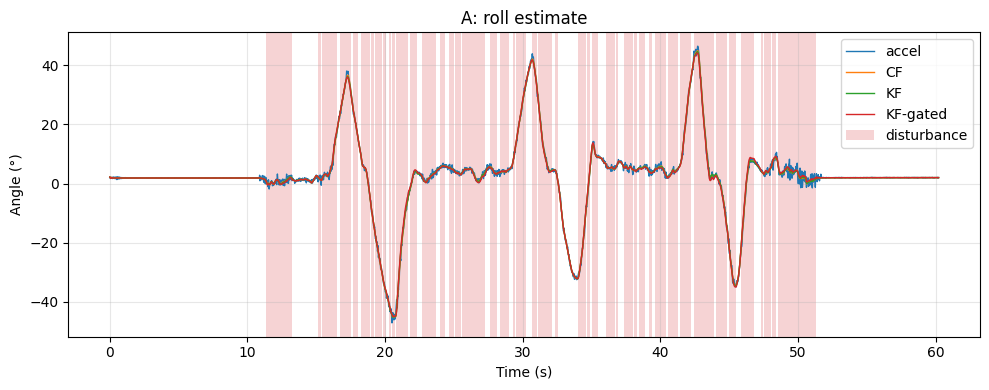

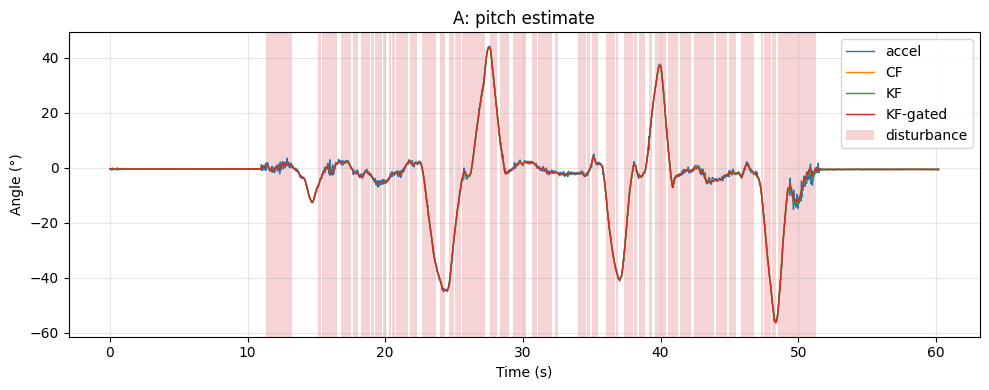

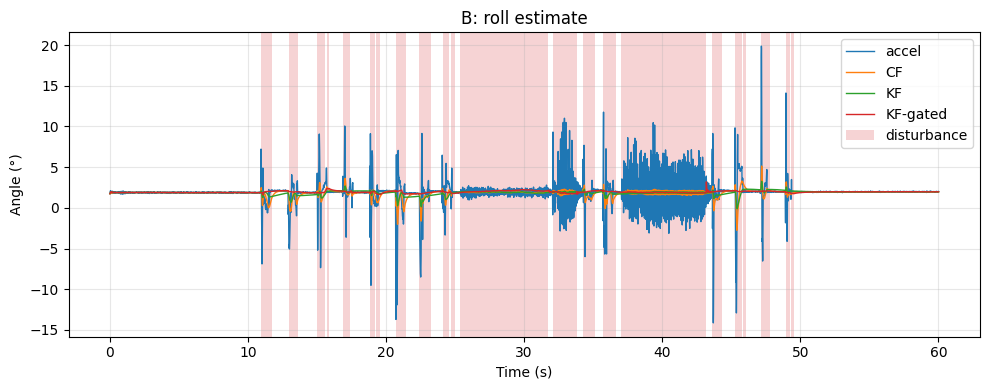

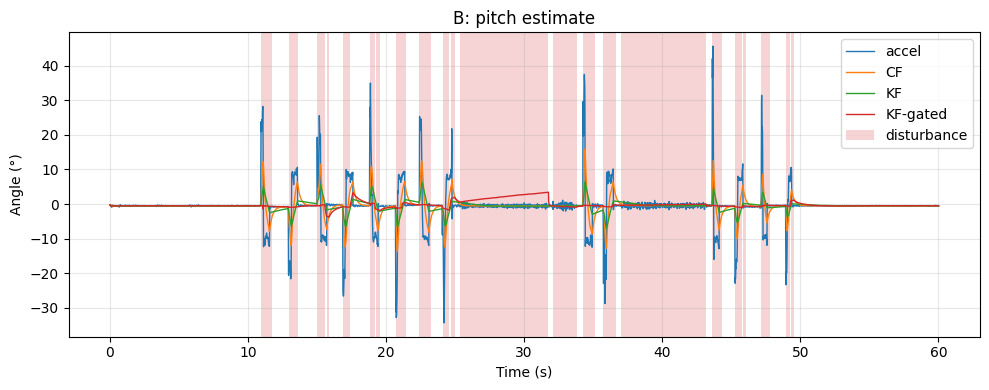

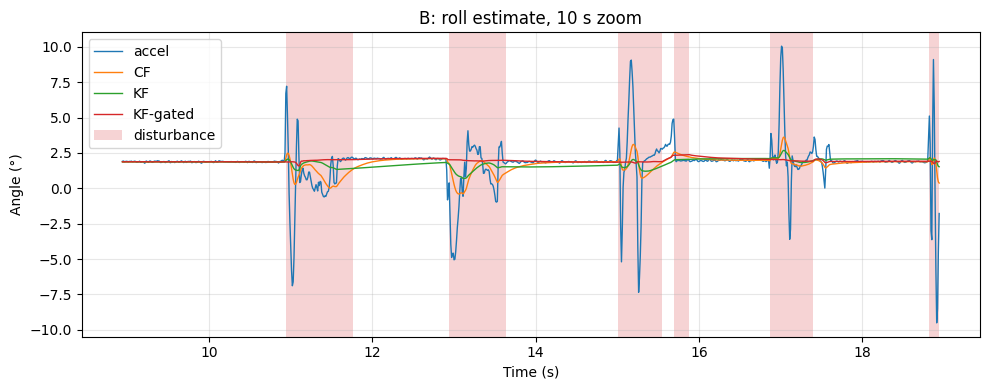

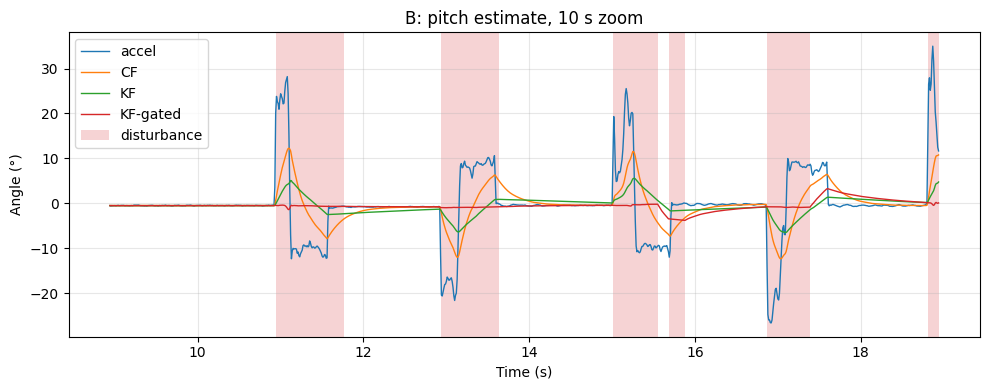

In [14]:
for key, r in real.items():
    for i, angle in enumerate(ANGLES):
        show(imu_plots.plot_estimates(r['t'], {n: r['ang'][n][i] for n in METHODS}, shade=r['kfg'].gated,
                                      title='%s: %s estimate' % (key, angle)))

# one zoom: recording B around the first gated sample
rb = real['B']
idx = np.nonzero(rb['kfg'].gated)[0]
z0 = rb['t'][idx[0]] - 2.0 if len(idx) else rb['t'][0] + 7.0
zm = (rb['t'] >= z0) & (rb['t'] <= z0 + 10.0)
for i, angle in enumerate(ANGLES):
    show(imu_plots.plot_estimates(rb['t'][zm], {n: rb['ang'][n][i][zm] for n in METHODS}, shade=rb['kfg'].gated[zm],
                                  title='B: %s estimate, 10 s zoom' % angle))

In [15]:
def window_mean(t, x, w0, w1):
    m = (t >= w0) & (t <= w1)
    return float(np.mean(x[m]))

for key, r in real.items():
    t = r['t']
    s0, s1 = r['window']
    e0, e1 = t[-1] - 7.0, t[-1] - 1.0
    print('%s: mean angles (deg), start window [%.1f, %.1f] s vs end window [%.1f, %.1f] s' % (key, s0, s1, e0, e1))
    print('%-10s%14s%14s%14s%14s' % ('method', 'roll start', 'roll end', 'pitch start', 'pitch end'))
    for name in METHODS:
        vals = []
        for i in range(2):
            x = r['ang'][name][i]
            vals += [DEG(window_mean(t, x, s0, s1)), DEG(window_mean(t, x, e0, e1))]
        print('%-10s%14.3f%14.3f%14.3f%14.3f' % (name, vals[0], vals[1], vals[2], vals[3]))
    print()

print('KF bias estimates (initial value from the rest window, and mean over the end window)')
print('%-4s%-9s%14s%14s%14s%14s' % ('set', 'axis', 'initial rad/s', 'initial deg/s', 'end rad/s', 'end deg/s'))
for key, r in real.items():
    t = r['t']
    for axis, series, init in (('b_x', r['kf'].bias_x, r['est'].gyro_bias[0]), ('b_y', r['kf'].bias_y, r['est'].gyro_bias[1])):
        end = window_mean(t, series, t[-1] - 7.0, t[-1] - 1.0)
        print('%-4s%-9s%14.6f%14.5f%14.6f%14.5f' % (key, axis, init, DEG(init), end, DEG(end)))

A: mean angles (deg), start window [1.0, 7.0] s vs end window [53.2, 59.2] s
method        roll start      roll end   pitch start     pitch end
accel              1.873         1.990        -0.448        -0.586
CF                 1.873         1.991        -0.449        -0.586
KF                 1.871         1.991        -0.451        -0.585
KF-gated           1.871         1.988        -0.451        -0.589

B: mean angles (deg), start window [1.0, 7.0] s vs end window [53.0, 59.0] s
method        roll start      roll end   pitch start     pitch end
accel              1.880         1.973        -0.517        -0.506
CF                 1.880         1.974        -0.517        -0.506
KF                 1.880         1.974        -0.519        -0.510
KF-gated           1.880         1.977        -0.519        -0.517

KF bias estimates (initial value from the rest window, and mean over the end window)
set axis      initial rad/s initial deg/s     end rad/s     end deg/s
A   b_x           -

## Criteria values (seed 0 for simulated data)

Values behind the Tier 3 success criteria RP1-RP3, RX1-RX5 and RR1-RR5, printed in one place with their units.

In [16]:
m6 = sim6.t >= 20.0
print('S6 (clean run), samples with t >= 20 s')
for name in ('KF', 'KF-gated', 'CF'):
    vals = [DEG(imu_metrics.rmse(ang6[name][i][m6], truth6[i][m6])) for i in range(2)]
    print('  RMSE %-9s roll %.4f deg, pitch %.4f deg' % (name, vals[0], vals[1]))
bx = np.max(np.abs(kf6.bias_x[m6] - sim6.gyro_bias[0]))
by = np.max(np.abs(kf6.bias_y[m6] - sim6.gyro_bias[1]))
print('  RP3 max |bias_x - b_x| = %.3e rad/s (%.4f deg/s), max |bias_y - b_y| = %.3e rad/s (%.4f deg/s)' % (bx, DEG(bx), by, DEG(by)))

print()
print('S7 (disturbances)')
mx = {}
for name in METHODS:
    mx[name] = max(DEG(imu_metrics.max_abs_error(ang7[name][i][dist7], truth7[i][dist7])) for i in range(2))
    print('  max disturbance error %-9s %.3f deg' % (name, mx[name]))
print('  RX2 ratio KF-gated / KF = %.3f;  RX3 ratio KF-gated / CF = %.3f' % (mx['KF-gated'] / mx['KF'], mx['KF-gated'] / mx['CF']))
for name in ('CF', 'KF', 'KF-gated'):
    worst = max(max(recovery(ang7[name][i], truth7[i])) for i in range(2))
    print('  RX4 worst recovery time %-9s %.2f s' % (name, worst))
q = [DEG(imu_metrics.rmse(ang7['KF-gated'][i][quiet7], truth7[i][quiet7])) for i in range(2)]
print('  RX5 quiet RMSE KF-gated: roll %.4f deg, pitch %.4f deg' % (q[0], q[1]))

print()
print('Real recordings')
for key, r in real.items():
    t, rec, est = r['t'], r['rec'], r['est']
    sp_a = np.median(np.diff(rec.accel_t))
    sp_g = np.median(np.diff(rec.gyro_t))
    print(' %s RR1: accel %d samples (median spacing %.5f s), gyro %d samples (median spacing %.5f s), common grid %.1f s'
          % (key, len(rec.accel_t), sp_a, len(rec.gyro_t), sp_g, t[-1] - t[0]))
    w0, w1 = r['window']
    wm = (t >= w0) & (t <= w1)
    gstd = np.std(r['gyro'][wm], axis=0, ddof=1)
    print(' %s RR2: gravity %.4f m/s^2, gyro std per axis %s rad/s, |gyro bias| per axis %s rad/s, accel noise std %.4f m/s^2'
          % (key, est.gravity, np.round(gstd, 5), np.round(np.abs(est.gyro_bias), 5), est.accel_noise_std))
    cf_int = imu_filters.complementary_roll_pitch(t, r['gyro'], r['accel'], tau=1e9, gyro_bias=est.gyro_bias)
    acc = imu_filters.accel_tilt(r['accel'])
    cr = [np.corrcoef(cf_int[i], acc[i])[0, 1] for i in range(2)]
    print(' %s RR3: Pearson r (Euler-mapped gyro integration vs accel tilt): roll %.4f, pitch %.4f' % (key, cr[0], cr[1]))
    e0, e1 = t[-1] - 7.0, t[-1] - 1.0
    for i, angle in enumerate(ANGLES):
        kg = r['ang']['KF-gated'][i]
        d4 = abs(DEG(window_mean(t, kg, e0, e1) - window_mean(t, kg, w0, w1)))
        d5 = abs(DEG(window_mean(t, kg, e0, e1) - window_mean(t, acc[i], e0, e1)))
        print(' %s %-5s RR4 |end - rest-window mean| = %.3f deg;  RR5 |KF-gated - accel tilt| in end window = %.3f deg' % (key, angle, d4, d5))

S6 (clean run), samples with t >= 20 s
  RMSE KF        roll 0.0368 deg, pitch 0.0270 deg
  RMSE KF-gated  roll 0.0368 deg, pitch 0.0270 deg
  RMSE CF        roll 0.0532 deg, pitch 0.0453 deg
  RP3 max |bias_x - b_x| = 5.018e-04 rad/s (0.0288 deg/s), max |bias_y - b_y| = 4.580e-04 rad/s (0.0262 deg/s)

S7 (disturbances)
  max disturbance error accel     19.915 deg
  max disturbance error CF        17.460 deg
  max disturbance error KF        12.449 deg
  max disturbance error KF-gated  3.028 deg
  RX2 ratio KF-gated / KF = 0.243;  RX3 ratio KF-gated / CF = 0.173
  RX4 worst recovery time CF        0.51 s
  RX4 worst recovery time KF        2.42 s
  RX4 worst recovery time KF-gated  1.21 s
  RX5 quiet RMSE KF-gated: roll 0.0339 deg, pitch 0.0278 deg

Real recordings
 A RR1: accel 6020 samples (median spacing 0.01000 s), gyro 6020 samples (median spacing 0.01000 s), common grid 60.2 s
 A RR2: gravity 9.8417 m/s^2, gyro std per axis [0.00076 0.00073 0.00073] rad/s, |gyro bias| per axis [6

## Interactive section

Controls: dataset (S6, S7, A, B), CF tau (log scale 0.02-2 s), KF process-noise scale sQ and measurement-noise scale sR (log scale 0.01-100; gyro noise and bias random walk scale with sqrt(sQ), accelerometer noise with sqrt(sR), as in the Tier 2 tuning sweep), a gating checkbox and the gate threshold (0.05-2 m/s^2). The data is loaded once above. The first cell below draws the output for the default control values statically (so it also appears when the notebook is executed without a live front end); the second cell creates the live widgets.

Initial output for the default control values:
S7: tau = 0.2 s, sQ = 1, sR = 1, gating = True (threshold 0.20 m/s^2)
method     roll RMSE (deg)  pitch RMSE (deg)   (t >= 20 s)
accel               2.3332            2.2640
CF                  1.5913            1.4558
KF                  0.3444            0.2626
max abs error inside disturbances (deg): accel roll 19.92, accel pitch 17.52, CF roll 17.46, CF pitch 16.29, KF roll 3.03, KF pitch 2.46


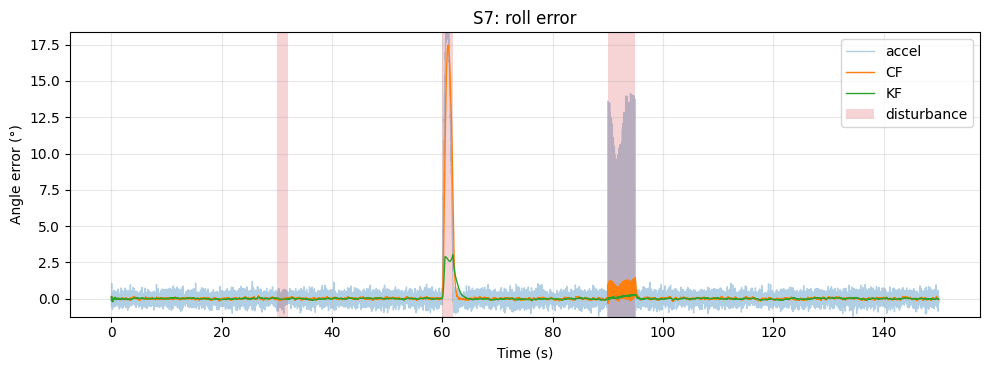

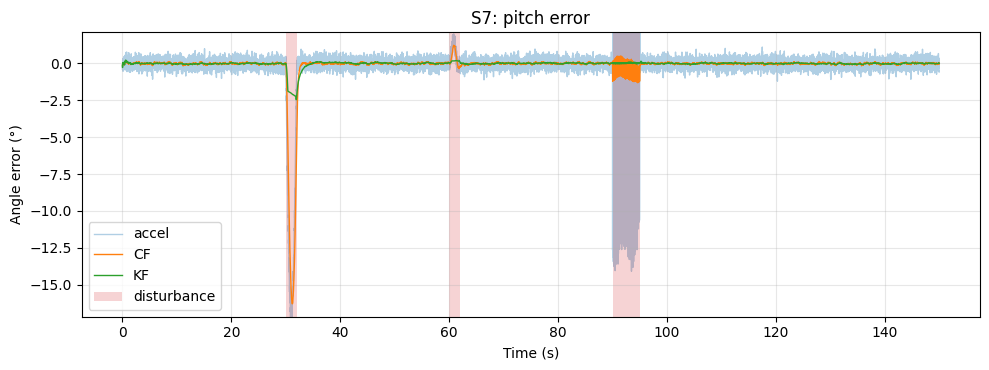

In [17]:
DATASETS = {
    'S6': dict(t=sim6.t, gyro=sim6.gyro, accel=sim6.accel, window=(0.0, 4.5), truth=truth6, shade=None, dist=None),
    'S7': dict(t=sim7.t, gyro=sim7.gyro, accel=sim7.accel, window=(0.0, 4.5), truth=truth7, shade=dist7, dist=dist7),
    'A': dict(t=real['A']['t'], gyro=real['A']['gyro'], accel=real['A']['accel'], window=real['A']['window'], truth=None),
    'B': dict(t=real['B']['t'], gyro=real['B']['gyro'], accel=real['B']['accel'], window=real['B']['window'], truth=None),
}

def render(dataset, tau, q_scale, r_scale, gating, gate_threshold):
    d = DATASETS[dataset]
    t = d['t']
    est = imu_filters.estimate_stationary(t, d['gyro'], d['accel'], d['window'][0], d['window'][1])
    acc = imu_filters.accel_tilt(d['accel'])
    cf = imu_filters.complementary_roll_pitch(t, d['gyro'], d['accel'], tau=tau, gyro_bias=est.gyro_bias)
    kf = imu_filters.kalman_roll_pitch(
        t, d['gyro'], d['accel'],
        gyro_noise_std=est.gyro_noise_std * np.sqrt(q_scale), accel_noise_std=est.accel_noise_std * np.sqrt(r_scale),
        bias_rw_std=BIAS_RW_STD * np.sqrt(q_scale), gravity=est.gravity, gyro_bias_z=est.gyro_bias[2],
        initial_bias=(est.gyro_bias[0], est.gyro_bias[1]),
        gate_threshold=(gate_threshold if gating else None))
    ang = {'accel': acc, 'CF': cf, 'KF': (kf.roll, kf.pitch)}
    names = list(ang.keys())
    if d['truth'] is not None:
        m = t >= 20.0
        print('%s: tau = %.3g s, sQ = %.3g, sR = %.3g, gating = %s (threshold %.2f m/s^2)' % (dataset, tau, q_scale, r_scale, gating, gate_threshold))
        print('%-8s%18s%18s' % ('method', 'roll RMSE (deg)', 'pitch RMSE (deg)') + '   (t >= 20 s)')
        for n in names:
            vals = [DEG(imu_metrics.rmse(ang[n][i][m], d['truth'][i][m])) for i in range(2)]
            print('%-8s%18.4f%18.4f' % (n, vals[0], vals[1]))
        if d['dist'] is not None:
            print('max abs error inside disturbances (deg): ' + ', '.join(
                '%s %s %.2f' % (n, a, DEG(imu_metrics.max_abs_error(ang[n][i][d['dist']], d['truth'][i][d['dist']])))
                for n in names for i, a in enumerate(ANGLES)))
        for i, a in enumerate(ANGLES):
            show(imu_plots.plot_error_comparison(t, d['truth'][i], {n: ang[n][i] for n in names}, background=('accel',),
                                                 shade=d['shade'], title='%s: %s error' % (dataset, a)))
    else:
        s0, s1 = d['window']
        e0, e1 = t[-1] - 7.0, t[-1] - 1.0
        print('%s: tau = %.3g s, sQ = %.3g, sR = %.3g, gating = %s (threshold %.2f m/s^2)' % (dataset, tau, q_scale, r_scale, gating, gate_threshold))
        print('%-8s%14s%14s%14s%14s   (mean angle, deg)' % ('method', 'roll start', 'roll end', 'pitch start', 'pitch end'))
        for n in names:
            vals = []
            for i in range(2):
                vals += [DEG(window_mean(t, ang[n][i], s0, s1)), DEG(window_mean(t, ang[n][i], e0, e1))]
            print('%-8s%14.3f%14.3f%14.3f%14.3f' % (n, vals[0], vals[1], vals[2], vals[3]))
        for i, a in enumerate(ANGLES):
            show(imu_plots.plot_estimates(t, {n: ang[n][i] for n in names}, shade=kf.gated if gating else None,
                                          title='%s: %s estimate' % (dataset, a)))

print('Initial output for the default control values:')
render('S7', TAU, 1.0, 1.0, True, GATE_THRESHOLD)

In [18]:
w_dataset = widgets.Dropdown(options=['S6', 'S7', 'A', 'B'], value='S7', description='dataset')
w_tau = widgets.FloatLogSlider(value=TAU, base=10, min=np.log10(0.02), max=np.log10(2.0), step=0.05, description='CF tau (s)')
w_q = widgets.FloatLogSlider(value=1.0, base=10, min=-2, max=2, step=0.1, description='KF Q scale')
w_r = widgets.FloatLogSlider(value=1.0, base=10, min=-2, max=2, step=0.1, description='KF R scale')
w_gate = widgets.Checkbox(value=True, description='gating')
w_thr = widgets.FloatSlider(value=GATE_THRESHOLD, min=0.05, max=2.0, step=0.05, description='threshold')
controls = widgets.VBox([w_dataset, w_tau, w_q, w_r, w_gate, w_thr])
out = widgets.interactive_output(render, {'dataset': w_dataset, 'tau': w_tau, 'q_scale': w_q, 'r_scale': w_r,
                                          'gating': w_gate, 'gate_threshold': w_thr})
display(controls, out)

Output()

## Discussion

- **Clean run (S6).** With parameters estimated from the 4.5 s rest window, the KF and KF-gated give almost the same, very small errors (a few hundredths of a degree RMSE); gating has nearly no effect when nothing disturbs the sensor. The CF is a few times worse than the KF but still well below the raw accelerometer tilt. The KF bias estimates track the true 0.01 rad/s bias.
- **Gating at the rising flank of a pulse.** The gate fires when | ||f|| - g | exceeds 0.2 m/s^2. A *horizontal* acceleration a changes ||f|| only to second order (about a^2 / (2g)), so the threshold is reached only for a of about 2 m/s^2. During the first part of each 3 m/s^2 half-sine pulse the accelerometer therefore still reaches the filter ungated, and only after the gate closes (and for 0.2 s afterwards) is it suppressed. This is why the gated filter does not eliminate the disturbance error, although it reduces the maximum error strongly compared with the ungated KF and the CF.
- **CF vs KF recovery.** The CF has a short memory (tau = 0.2 s) and re-converges within about a second after a pulse, but it passes a much larger share of the accelerometer disturbance into the angle. The KF trusts the gyro more (its gain is small once the covariance has converged), so its disturbance error is smaller, at the cost of a longer recovery of a few seconds; gating shortens this recovery because less disturbance enters the state.
- **Vibration.** The 15 Hz vibration averages out in the accelerometer path and adds only a small artefact to the gyro; it is visible mainly in the CF and ungated KF while the gate is closed for the whole vibration segment.
- **Real data A and B.** The rest-window table shows the estimated bias, noise levels and local gravity. Check the start-vs-end tables: both recordings end in the starting pose and heading, so each method's roll and pitch should return close to the start values; the KF angles should also agree with the accelerometer tilt in the still end window. In recording B the shaded spans show where the gate closed; compare the KF and KF-gated curves there.
- **Interactive section.** Increasing the CF tau or the KF R scale makes the filters trust the accelerometer less (smoother, slower to correct); a larger Q scale makes the KF follow the accelerometer more. Disabling gating on S7 shows the full disturbance error.